# 双通道 FRET：人工复筛

自动判据只能看数字，看不出"孔里有第二个分子在闪""背景环被邻居污染""漂白点落在一次闪光
的尾巴上"这类结构问题。粗筛已把每视野压到 **10 条上下**，摊开看一眼比继续调阈值划算。

- **输入**：`<sif 主名>_fret/` 里的 `fret.csv`（E 与判据量）＋ `good_traces.csv`（trace 本体）
- **输出**：同目录下的 `*_manual.*`，**机器筛的产物一个字节都不动**

| 文件 | 内容 |
|---|---|
| `fret_manual.csv` | 人工筛后的逐分子 E（列与 `fret.csv` 相同） |
| `E_distribution_manual.png` | 人工筛后的 E 分布 |
| `good_traces_manual.png` | 留下的 trace 总览 |
| `good_traces_manual.csv` | 留下的 trace（可再读回） |
| `rejected_traces_manual.png` | **被删掉的** trace（留证据） |
| `manual_reject.json` | 删了哪些编号 —— 重启内核后自动读回来，不会把删掉的又放回来 |

γ/α/β **沿用 `fret.csv` 里的值**，这一步不重估 —— 否则人工筛完的 E 与机器筛的不可比。


In [ ]:
# `import smlm` 需要 Py_Smile 在 sys.path 上; notebook 放在子目录里时自己找一下
import json
import pathlib
import sys

for _q in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]:
    if (_q / 'smlm' / '__init__.py').is_file():
        sys.path.insert(0, str(_q))
        break

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import smlm.fret as fr
from smlm.datatypes import Trace

plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

# ======================= 输入 =======================
BASE_DIR = pathlib.Path(r"G:\PacBio\近观DNA_FRET\20261123")
SUFFIX = '_manual'          # 输出文件名后缀

# ======================= 池化分组 =======================
# 组名 -> 视野关键字列表 (空列表 = 该组用全部视野); 每组写到 STATS_DIR/<组名>/
GROUPS = {
    'all': ['sample32_532nm_2mW_0p1S_2000frames_fov1',
            'sample32_532nm_2mW_0p1S_2000frames_fov2',
            'sample32_532nm_2mW_0p1S_2000frames_fov3',
            'sample32_532nm_2mW_0p1S_2000frames_fov4',
            'sample32_532nm_2mW_0p1S_2000frames_fov5',
            'sample32_532nm_2mW_0p1S_2000frames_fov6'],
    # 'fov1_fov4': ['fov1', 'fov4'],
}
STATS_DIR = BASE_DIR / 'FRET_stats'

# 一般不用手填: 勾选的结果会存进各目录的 manual_reject.json, 重跑时自动读回
REJECT = {}

print('BASE_DIR :', BASE_DIR)
print('视野     :', ', '.join(sorted(p.name[:-len("_fret")] for p in BASE_DIR.glob("*_fret"))))
print('分组     :', {k or '(空=全部)': v for k, v in GROUPS.items()})


BASE_DIR : G:\PacBio\近观DNA_FRET\20261123
视野     : sample32_532nm_2mW_0p1S_2000frames_fov1, sample32_532nm_2mW_0p1S_2000frames_fov2, sample32_532nm_2mW_0p1S_2000frames_fov3, sample32_532nm_2mW_0p1S_2000frames_fov4, sample32_532nm_2mW_0p1S_2000frames_fov5, sample32_532nm_2mW_0p1S_2000frames_fov6
分组     : {'all': ['sample32_532nm_2mW_0p1S_2000frames_fov1', 'sample32_532nm_2mW_0p1S_2000frames_fov2', 'sample32_532nm_2mW_0p1S_2000frames_fov3', 'sample32_532nm_2mW_0p1S_2000frames_fov4', 'sample32_532nm_2mW_0p1S_2000frames_fov5', 'sample32_532nm_2mW_0p1S_2000frames_fov6']}


## 读回粗筛结果

E 与判据量从 `fret.csv` 还原，trace 从 `good_traces.csv` 读，**按 `emitter_id` 对齐**（下标 ≠ 编号）。
删过的编号从 `manual_reject.json` 读回来 —— 所以重启内核不会把已经删掉的分子又放回来。


In [ ]:
REJECT_FILE = 'manual_reject.json'


def field_dir(name):
    """<BASE_DIR>/<name>_fret, 不存在就报错 (不静默跳过)。"""
    d = BASE_DIR / f'{name}_fret'
    if not d.is_dir():
        raise FileNotFoundError(d)
    return d


def field_names():
    return sorted(p.name[:-len('_fret')] for p in BASE_DIR.glob('*_fret'))


def pick(keys):
    """按关键字挑视野; 空 = 全部。匹配不到就大声报错。"""
    names = field_names()
    if not keys:
        return names
    out = [n for n in names if any(k in n for k in keys)]
    if not out:
        raise ValueError(f'没有视野匹配 {keys}; 现有 {names}')
    return out


def read_reject(name):
    p = field_dir(name) / REJECT_FILE
    if not p.is_file():
        return []
    try:
        return sorted(int(v) for v in json.loads(
            p.read_text(encoding='utf-8')).get('rejected', []))
    except (ValueError, TypeError):
        print(f'  [!] {p} 读不动, 当成没有删过')
        return []


def write_reject(name, ids):
    p = field_dir(name) / REJECT_FILE
    p.write_text(json.dumps({'rejected': sorted(int(i) for i in ids)},
                            ensure_ascii=False, indent=1), encoding='utf-8')
    return p


def _trace_from(arr, k, emitter_id):
    idd = np.asarray(arr['I_donor'][k], float)
    return Trace(emitter_id=int(emitter_id), frames=np.arange(idd.size),
                 x=float(arr['x_px'][k, 0]), y=float(arr['y_px'][k, 0]),
                 intensity=idd, bg_flux=np.asarray(arr['bg_donor'][k], float),
                 raw=idd + np.asarray(arr['bg_donor'][k], float))


def _trace_a_from(arr, k, emitter_id):
    ia = np.asarray(arr['I_acceptor'][k], float)
    return Trace(emitter_id=int(emitter_id), frames=np.arange(ia.size),
                 x=float(arr['x_px'][k, 0]), y=float(arr['y_px'][k, 0]),
                 intensity=ia, bg_flux=np.asarray(arr['bg_acceptor'][k], float),
                 raw=ia + np.asarray(arr['bg_acceptor'][k], float))


def load_field(name, verbose=True):
    """读回一个视野的粗筛结果。

    返回 ``(records, traces_d, traces_a, results, ex_time, cal)``。
    """
    d = field_dir(name)
    df = pd.read_csv(d / fr.FILES['fret_csv'], encoding='utf-8-sig')
    arr = fr.load_traces_csv(d / fr.FILES['traces_good'])
    pos = {int(v): k for k, v in enumerate(arr['emitter_id'])}

    recs, res, td, ta = [], [], [], []
    for row in df.itertuples():
        i = int(row.idx)
        if i not in pos:
            raise KeyError(f'{name}: traces csv 里没有 #{i}, 与 fret.csv 对不上')
        k = pos[i]
        td.append(_trace_from(arr, k, i))
        ta.append(_trace_a_from(arr, k, i))
        ev = fr.StepEvent(emitter_id=i, frame=int(row.frame_j), lag=int(row.lag),
                          IA_pre=float(row.I_A_pre), IA_post=float(row.I_A_post),
                          ID_pre=float(row.I_D_pre), ID_post=float(row.I_D_post),
                          dIA=float(row.I_A_pre - row.I_A_post),
                          dID=float(row.I_D_post - row.I_D_pre),
                          dID_long=np.nan)
        recs.append(fr.PairRecord(emitter_id=i, keep=True, event=ev,
                                  E=float(row.E), spread=float(row.spread),
                                  n_d_pre=int(row.n_d_pre),
                                  red_label=str(row.red_label),
                                  red_duty=float(row.red_duty),
                                  IA_max=float(row.I_A_pre)))
        res.append(fr.FretResult(
            emitter_id=i, frame=int(row.frame_j), lag=int(row.lag),
            x=float(row.x_px), y=float(row.y_px),
            n_pre=int(row.n_pre), n_on=int(row.n_on),
            IA_pre=float(row.I_A_pre), ID_pre=float(row.I_D_pre),
            IA_post=float(row.I_A_post), ID_post=float(row.I_D_post),
            S_A=float(row.S_A), E=float(row.E), E_don=float(row.E_don),
            snr_A=float(row.snr_A), t_bleach=float(row.t_bleach_s)))

    ex = float(arr['t_s'][0, 1] - arr['t_s'][0, 0])
    cal = fr.FretCalibration(gamma=float(df['gamma'].iloc[0]),
                             alpha=float(df['alpha'].iloc[0]),
                             beta=float(df['beta'].iloc[0]))
    REJECT.setdefault(name, read_reject(name))
    if verbose:
        drop = set(REJECT[name])
        print(f'{name}: 粗筛 {len(recs)} 条, 已删 {len(drop)} -> 留 {len(recs) - len(drop)}'
              f'   γ={cal.gamma:.2f} α={cal.alpha:.3f} β={cal.beta:+.1f}')
    return recs, td, ta, res, ex, cal


## 一页一个文件：勾上 = 剔除

翻页（或点"保存本页"）时**自动落盘**到该视野自己的 `<sif 主名>_fret/` 下，不用再跑别的格。
勾选框上的 `#id / E` 与图上标题一一对应；`✗` 表示"这条不要"。

- 状态行会写"已保存 / 未保存"，未保存就换页会自动先存；
- 删掉的编号存进 `manual_reject.json`，重启内核后自动恢复；
- 想重新开始就删掉该目录下的 `manual_reject.json`（页面上取消勾选也一样）。


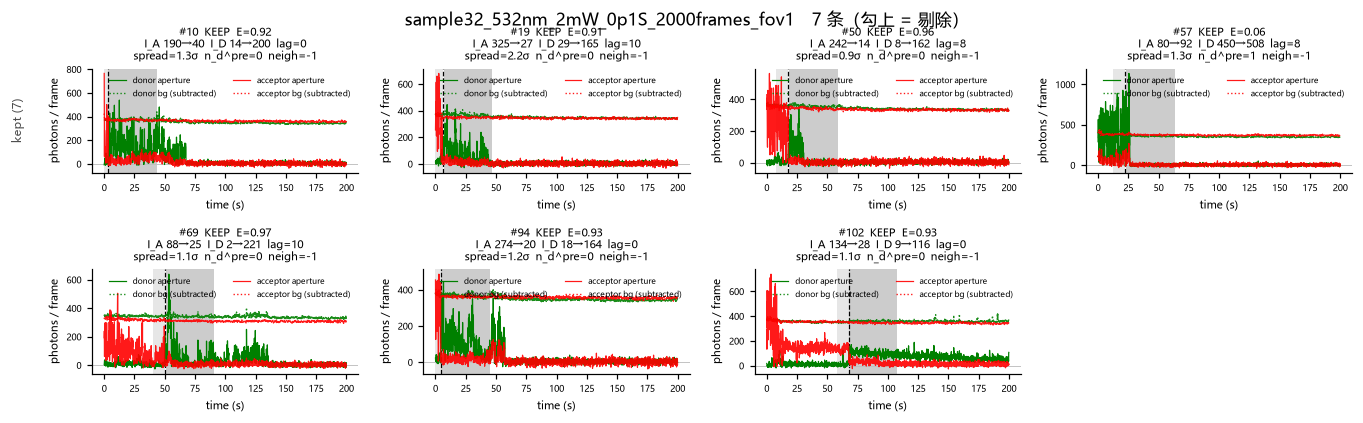

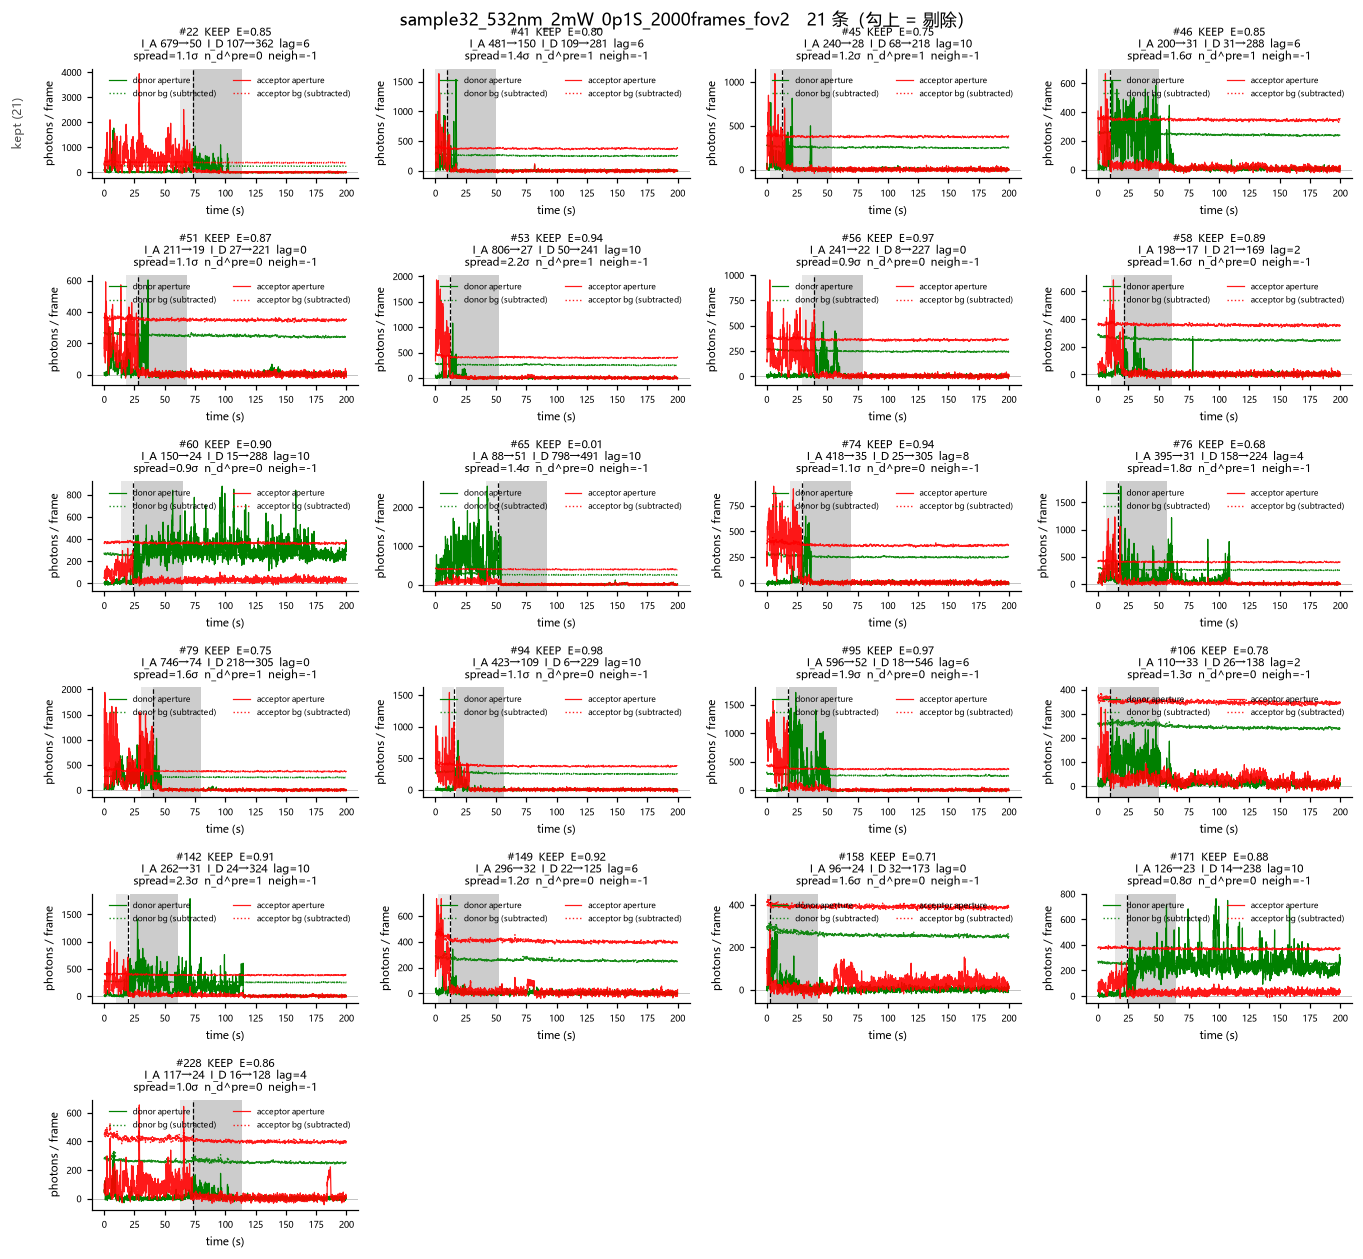

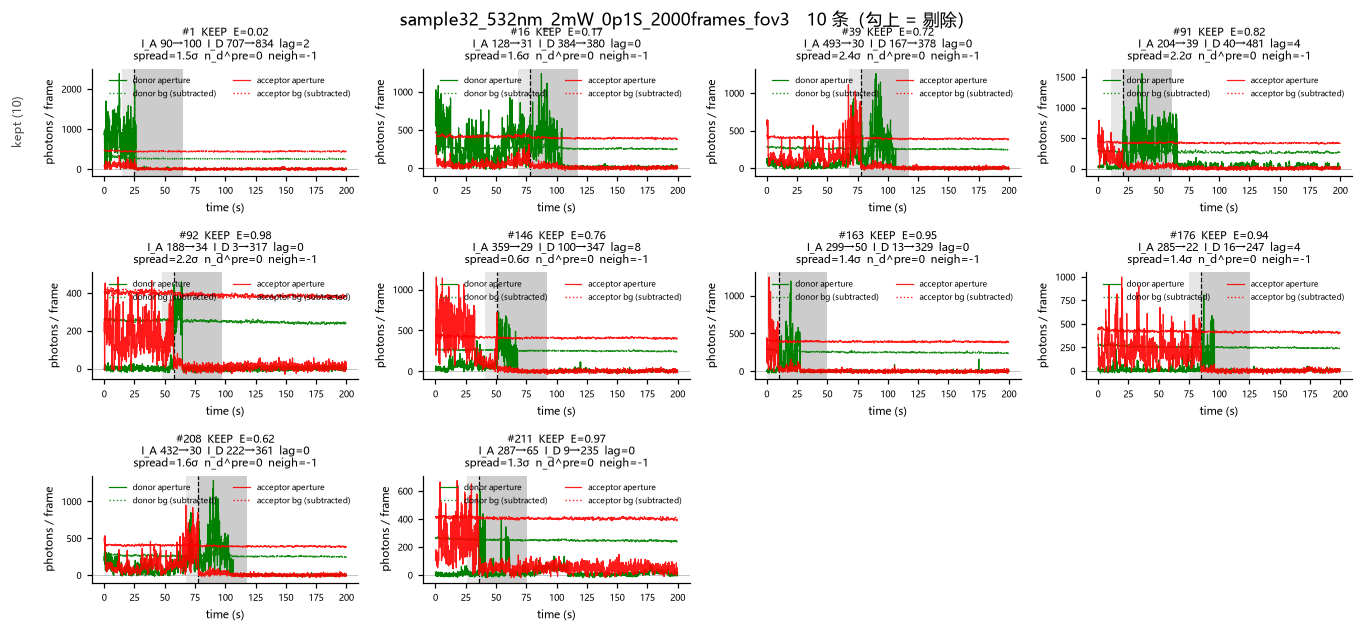

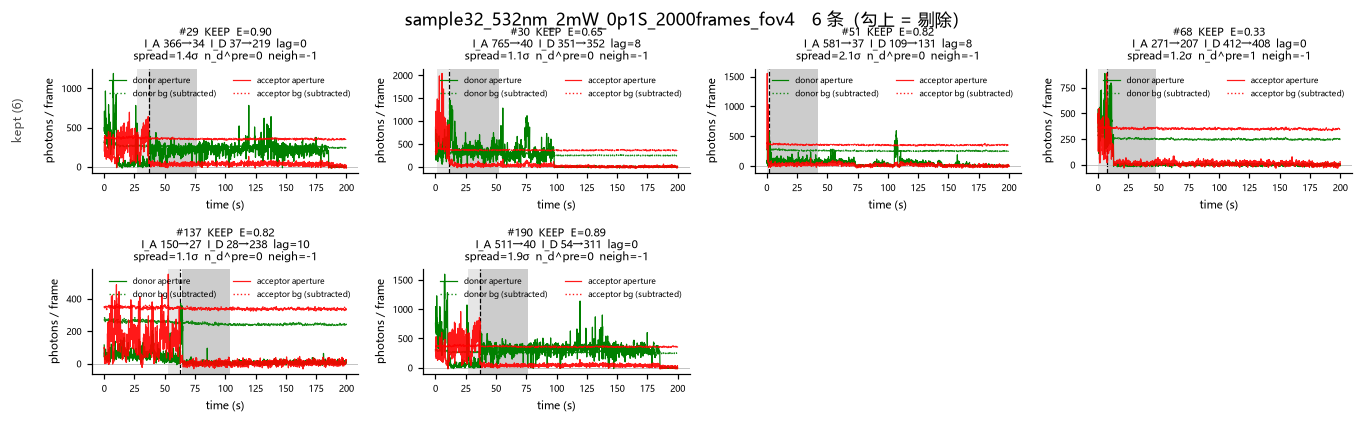

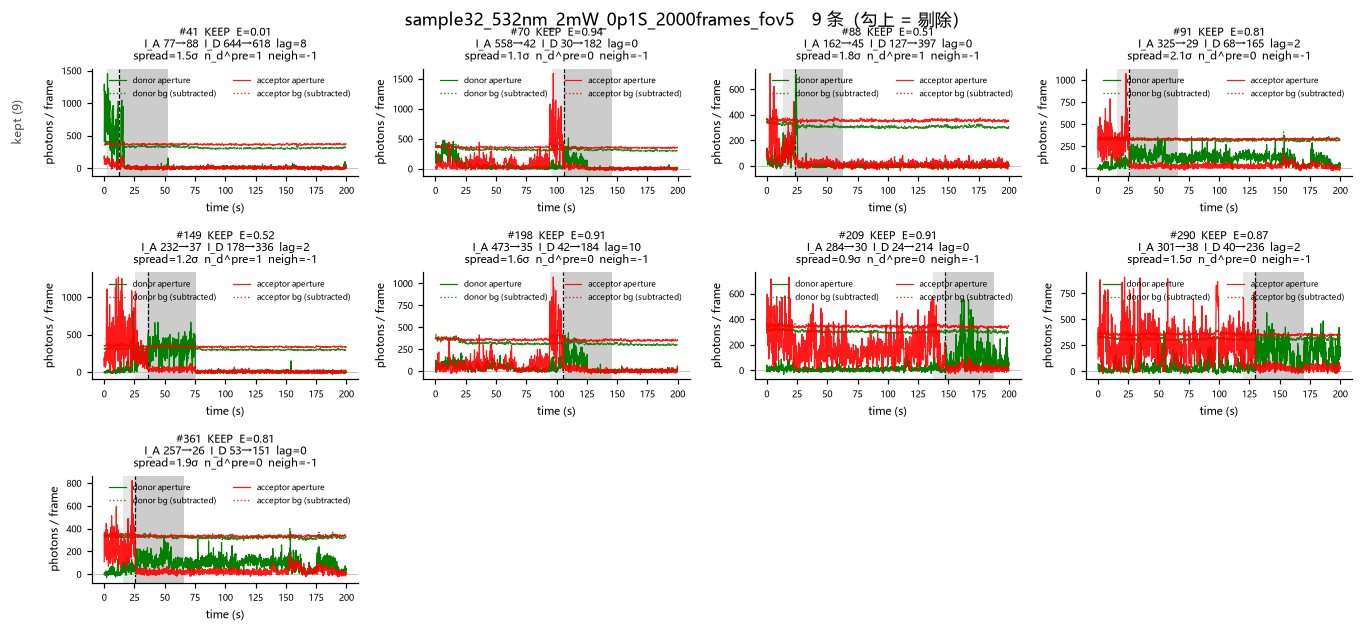

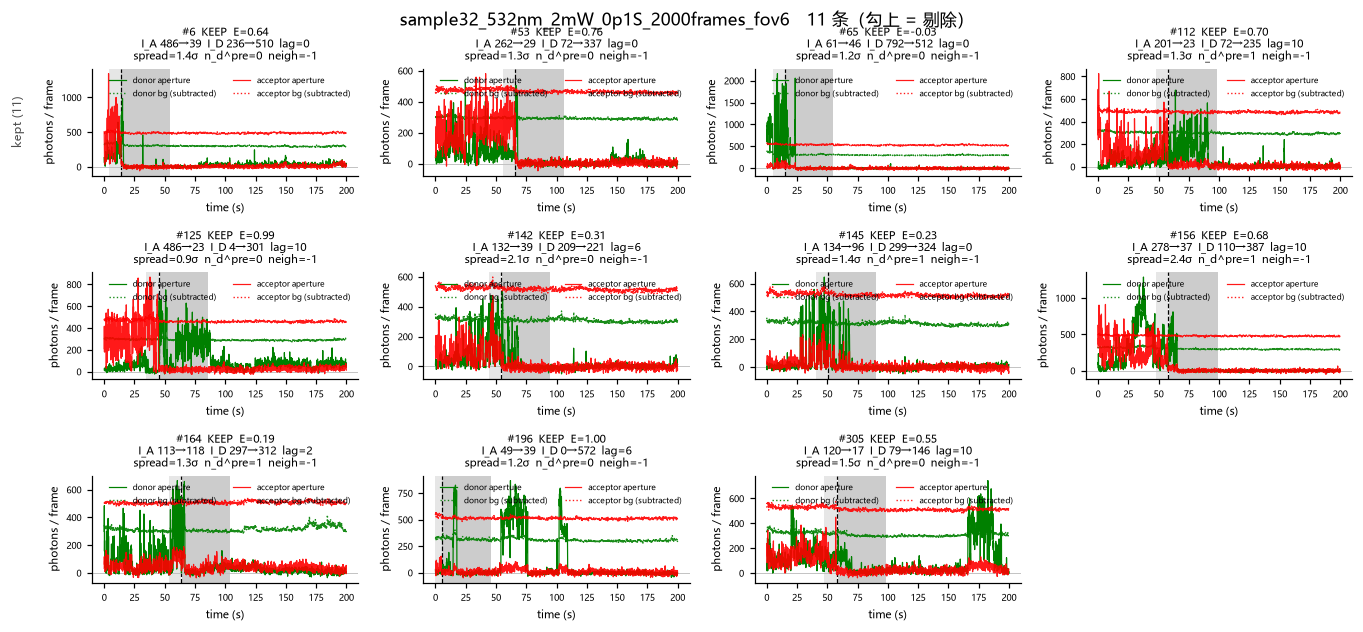

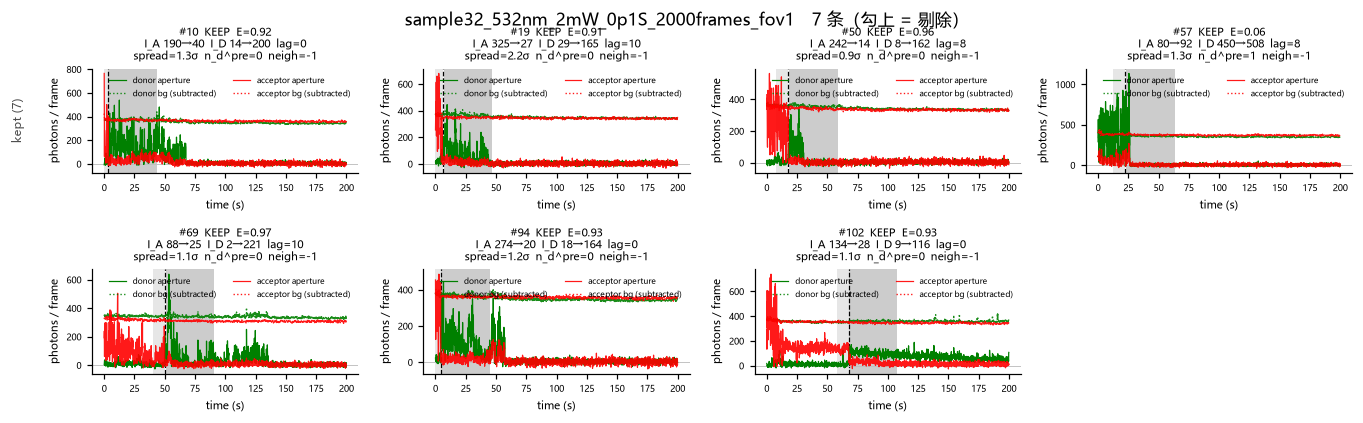

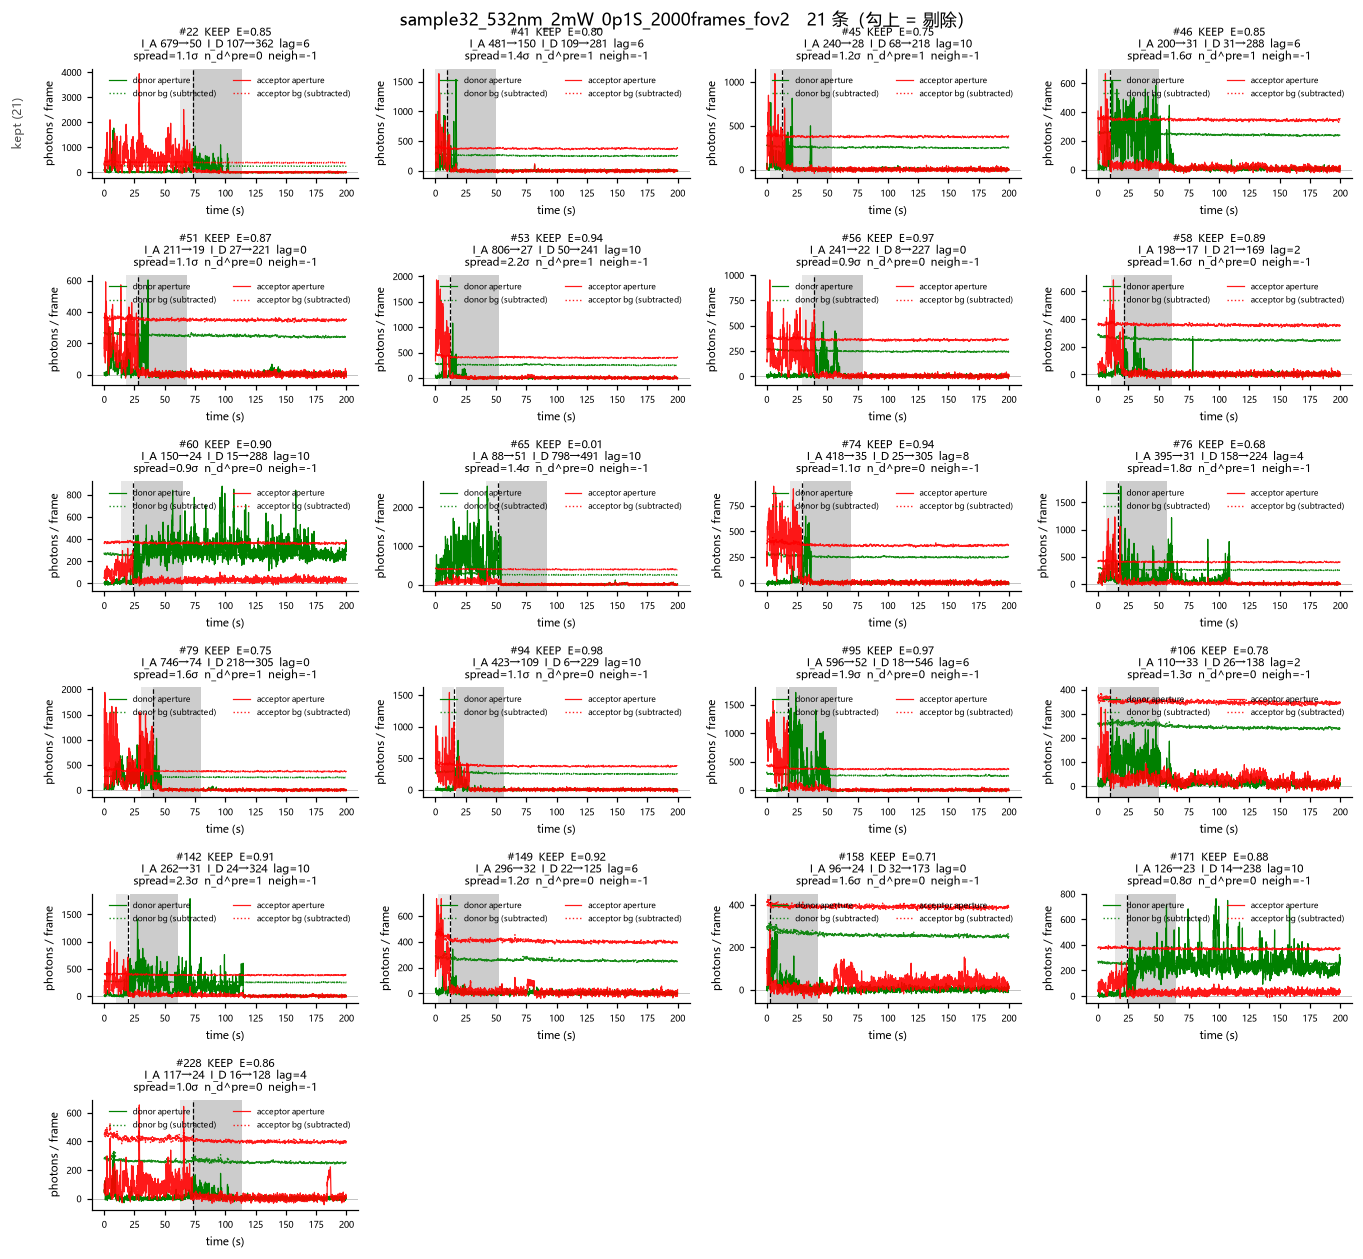

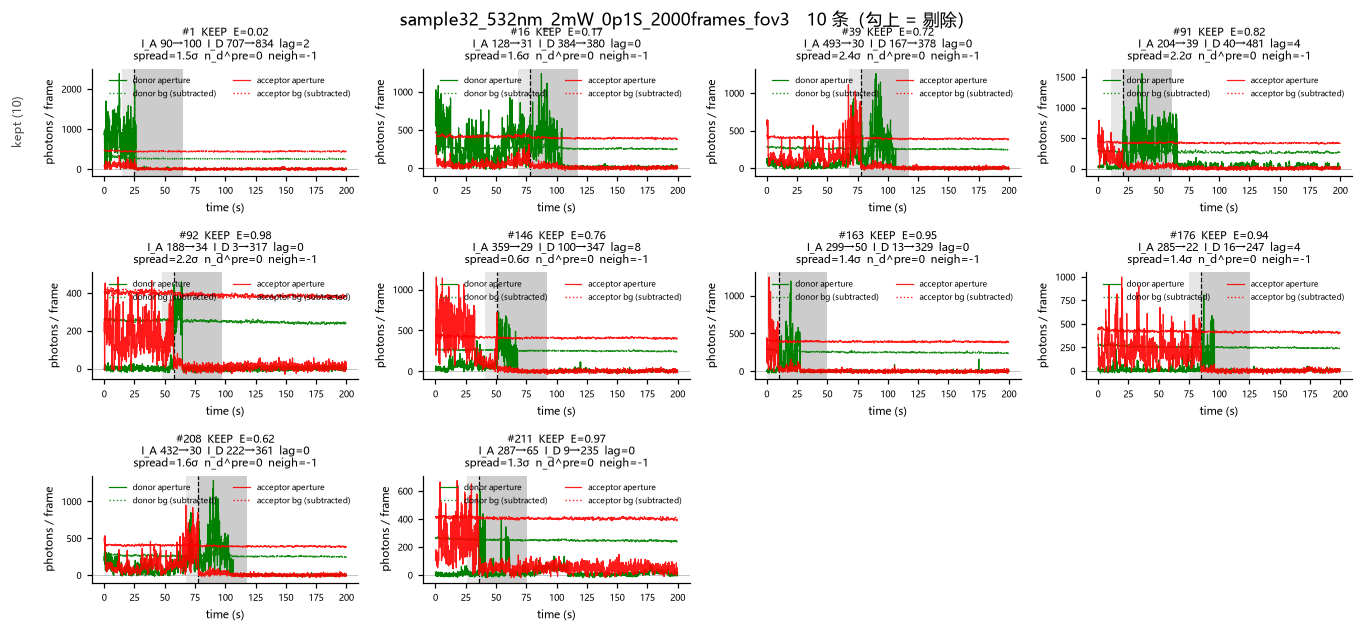

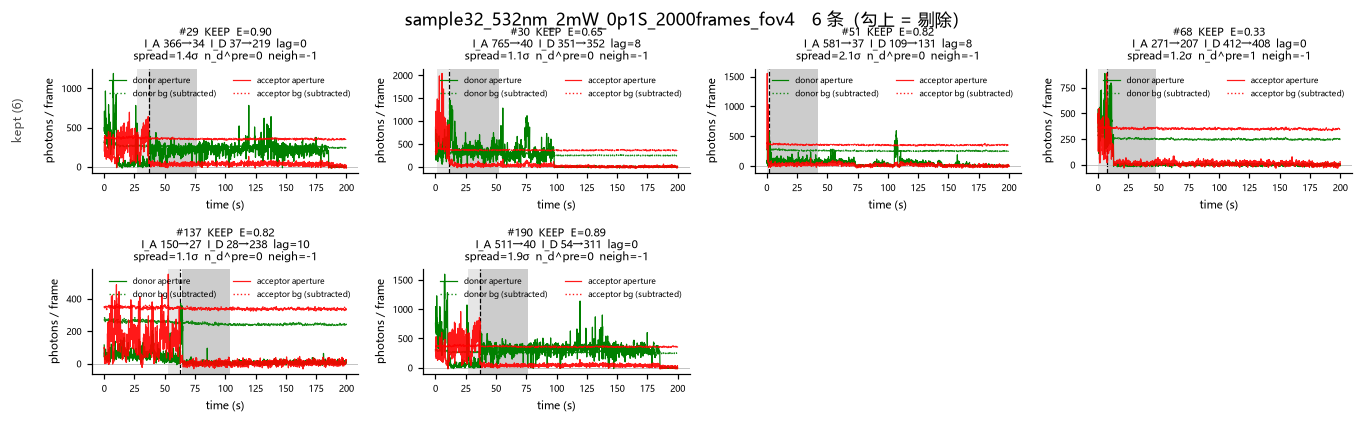

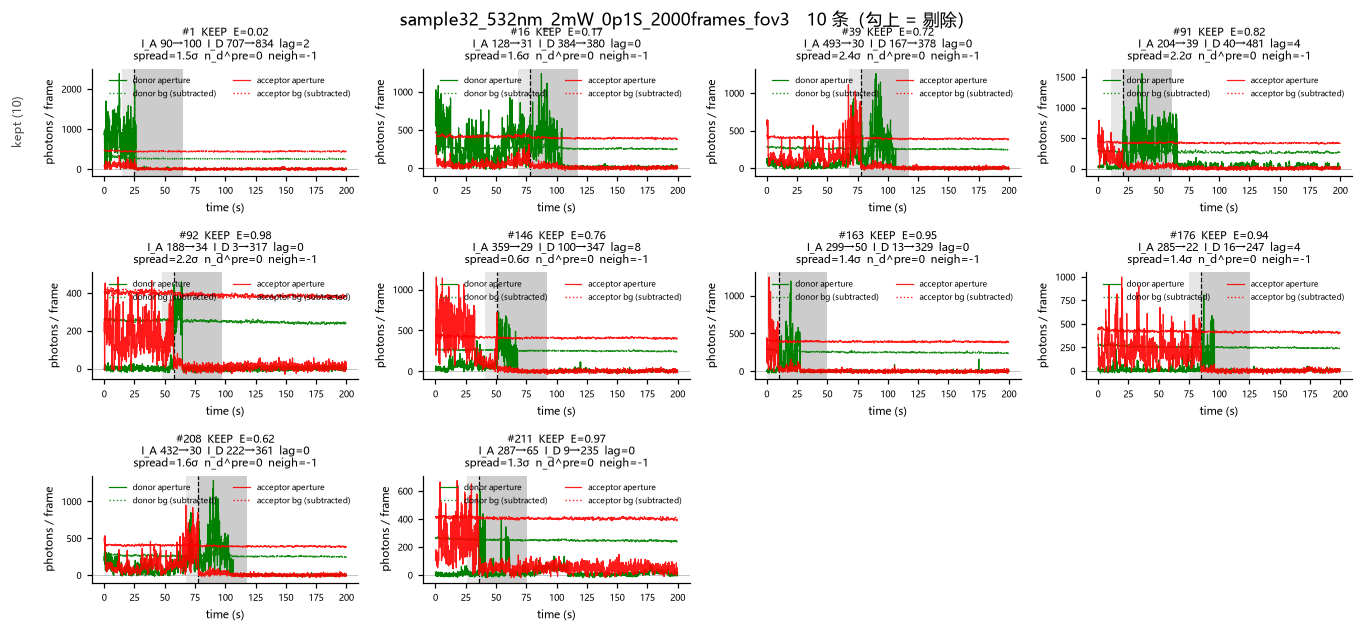

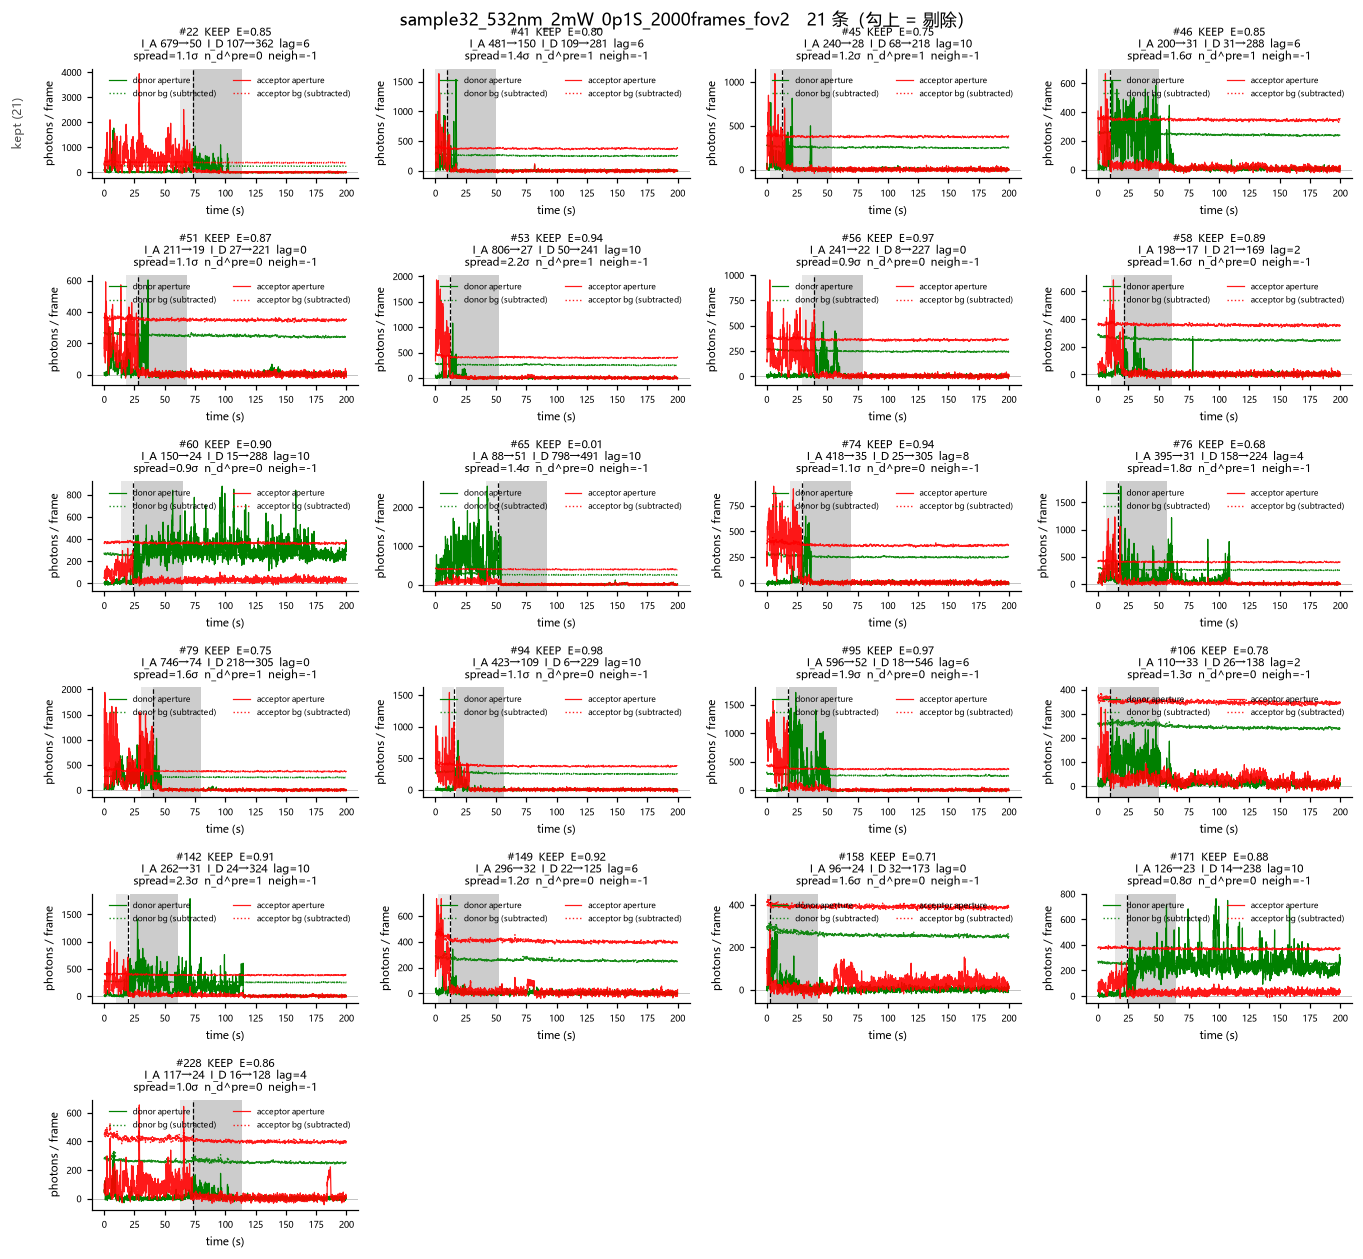

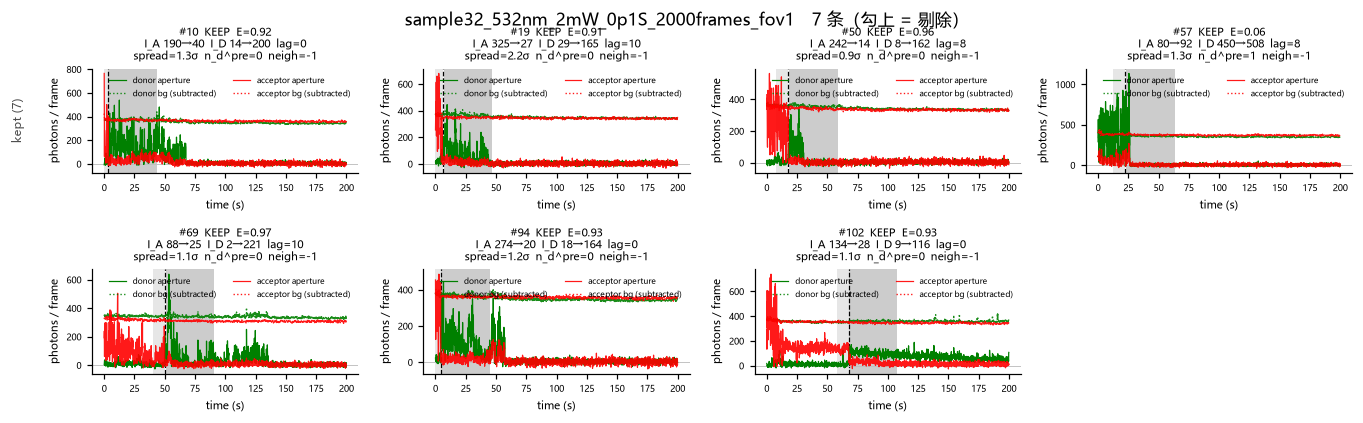

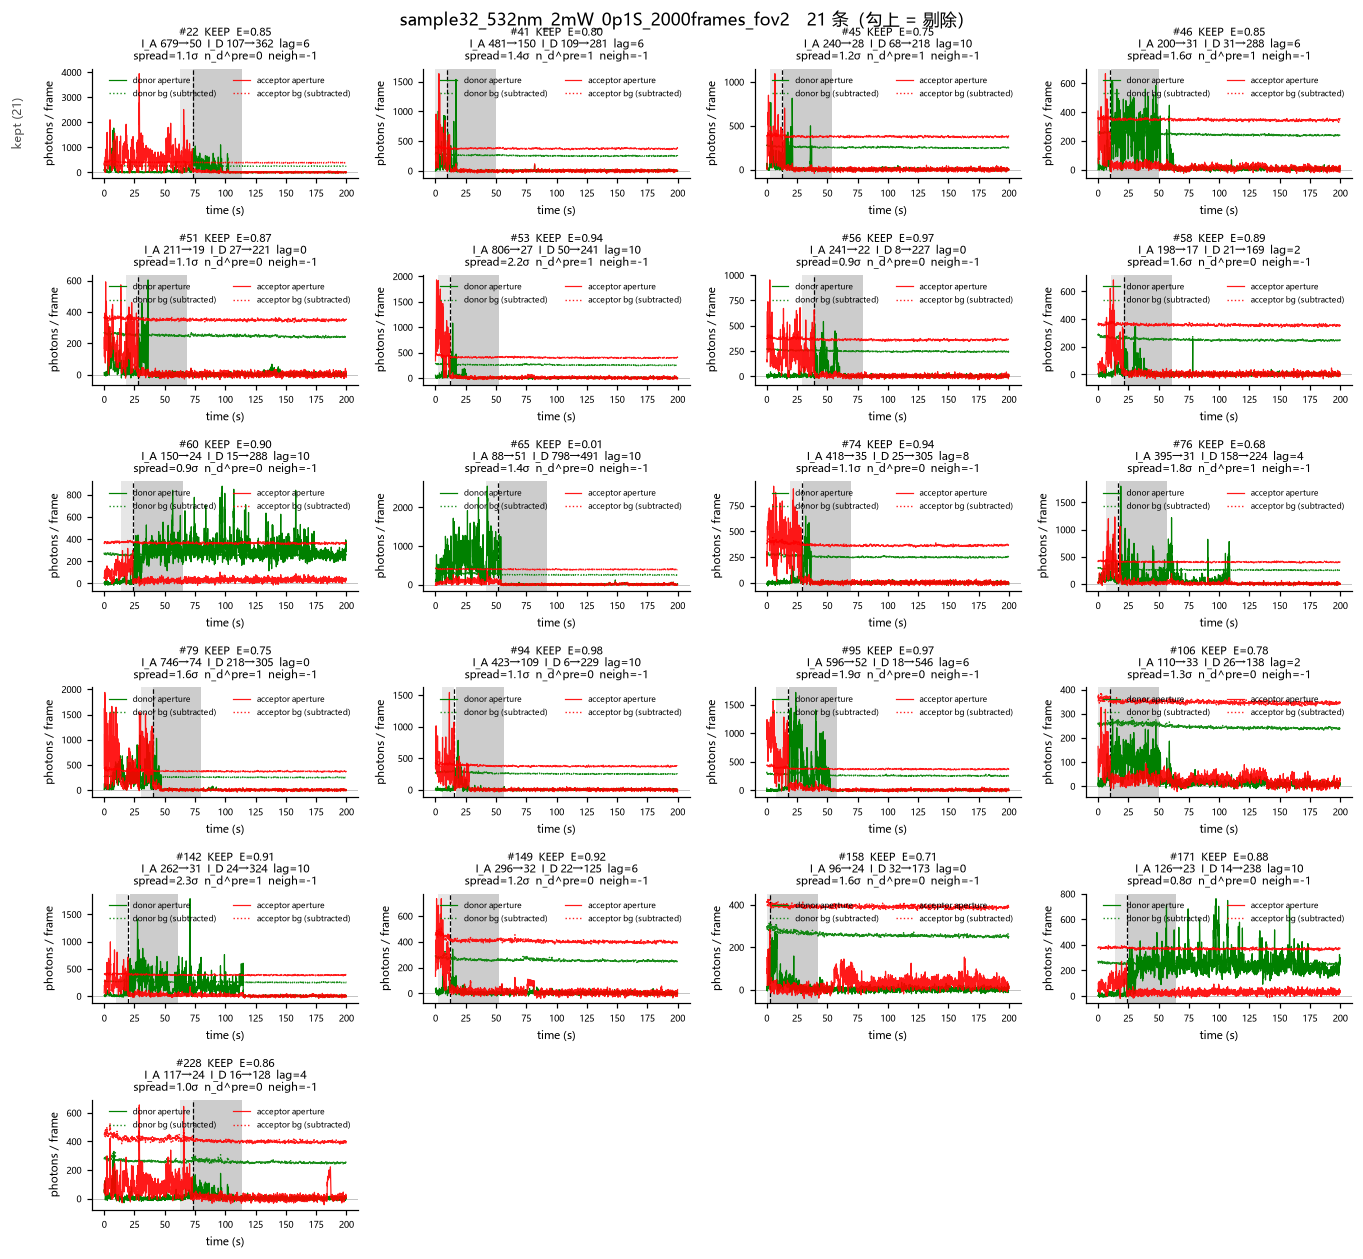

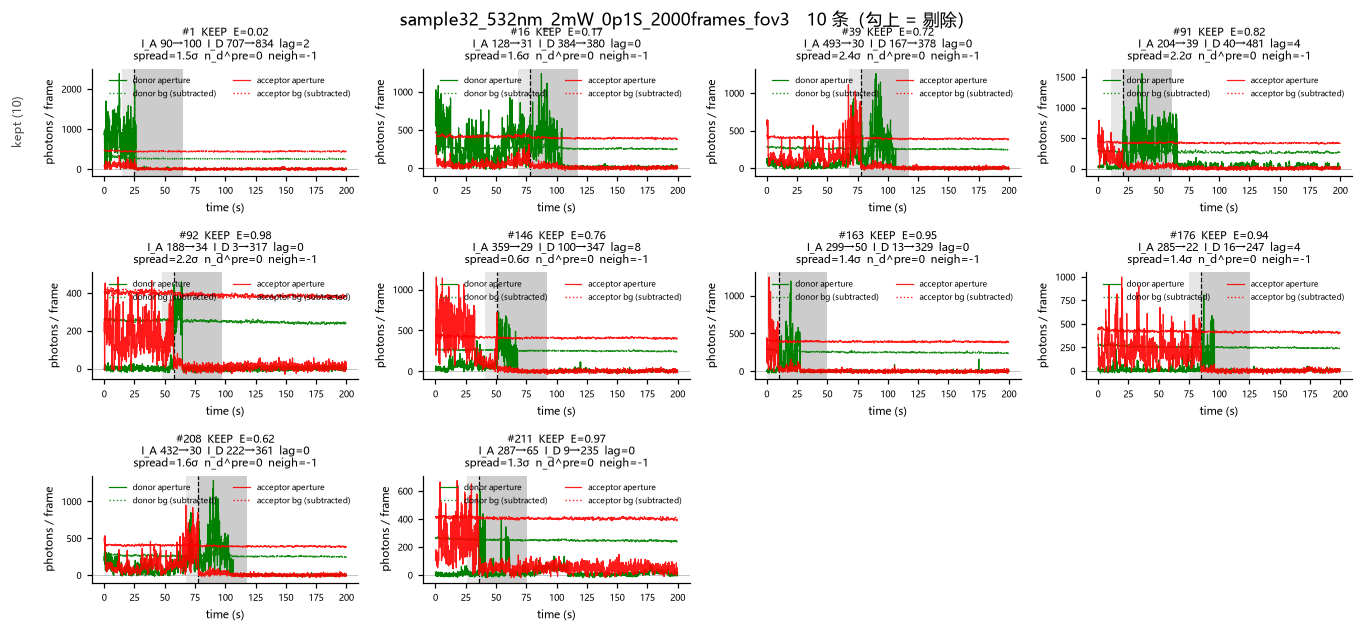

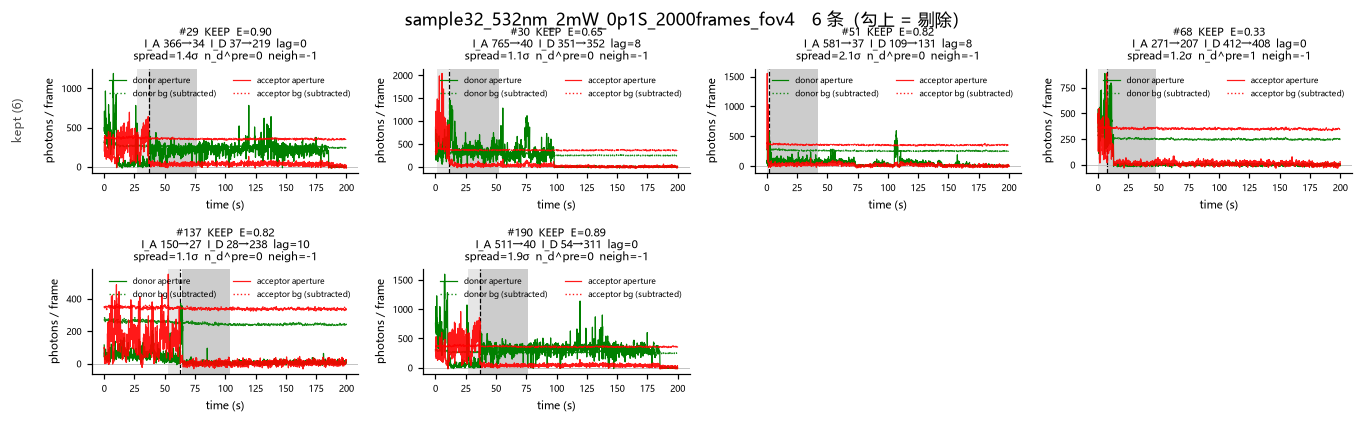

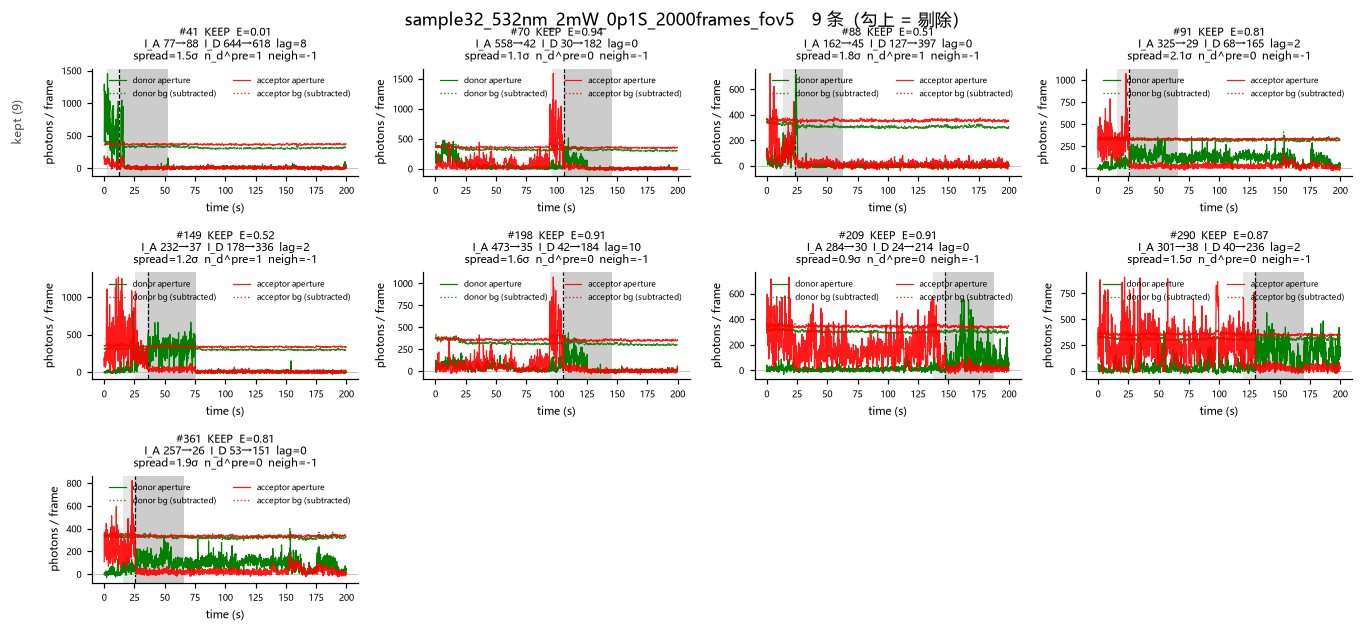

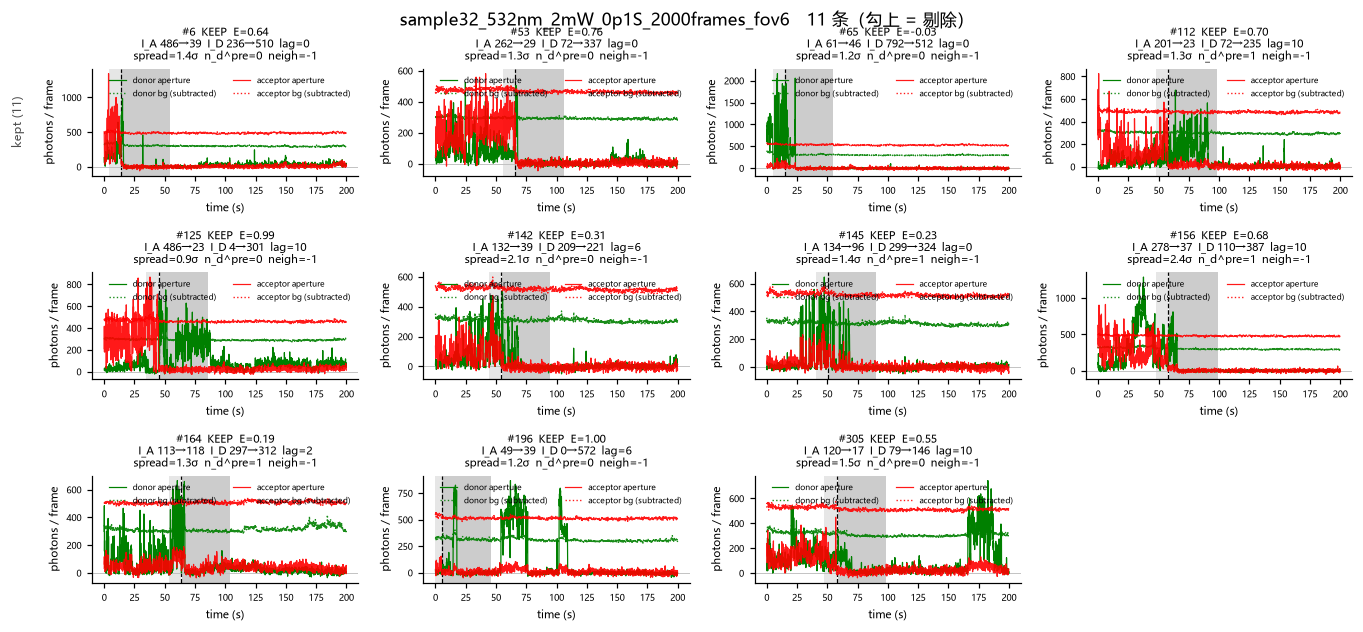

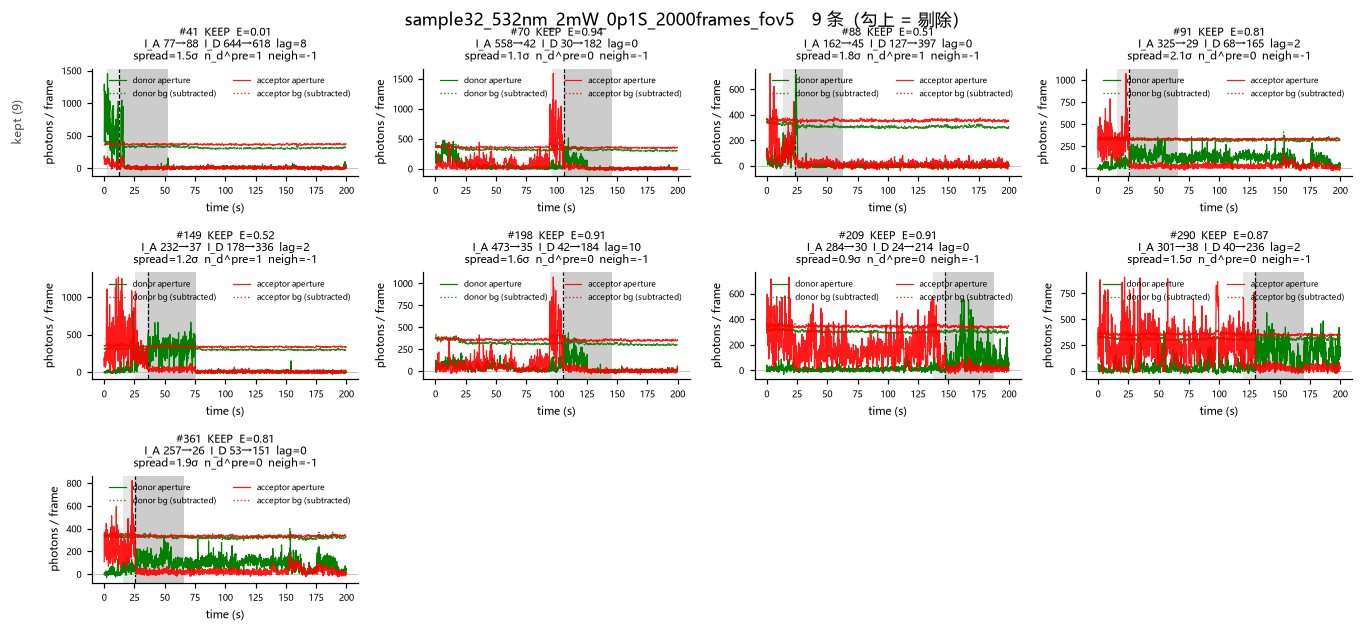

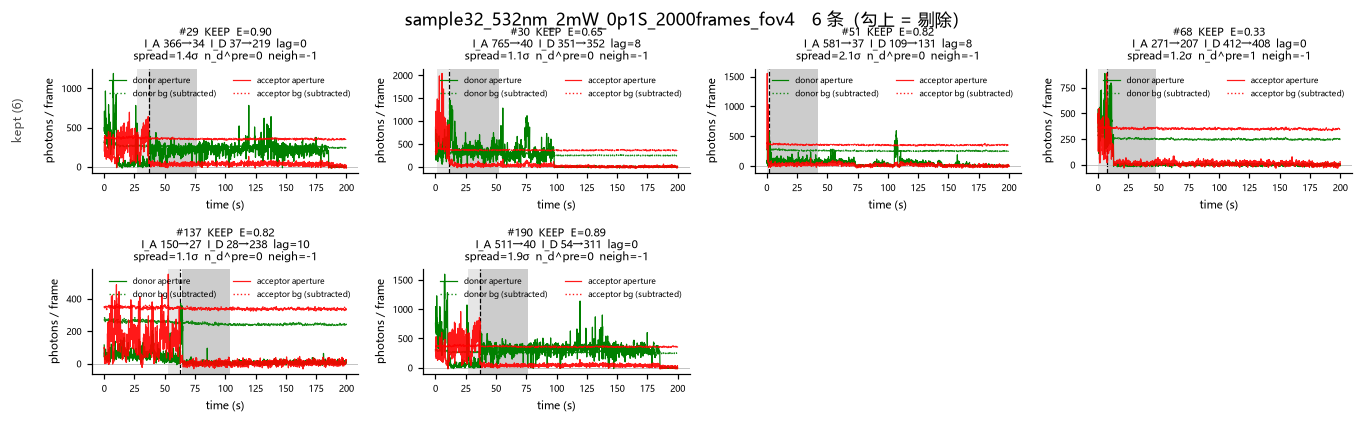

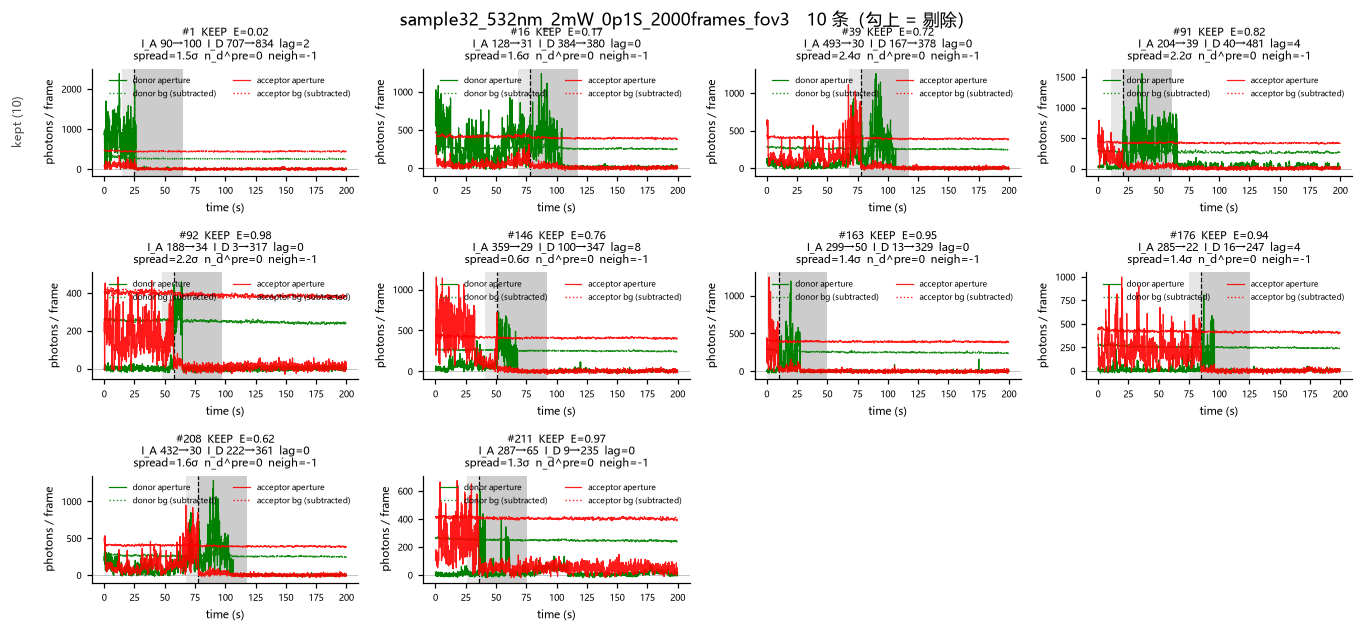

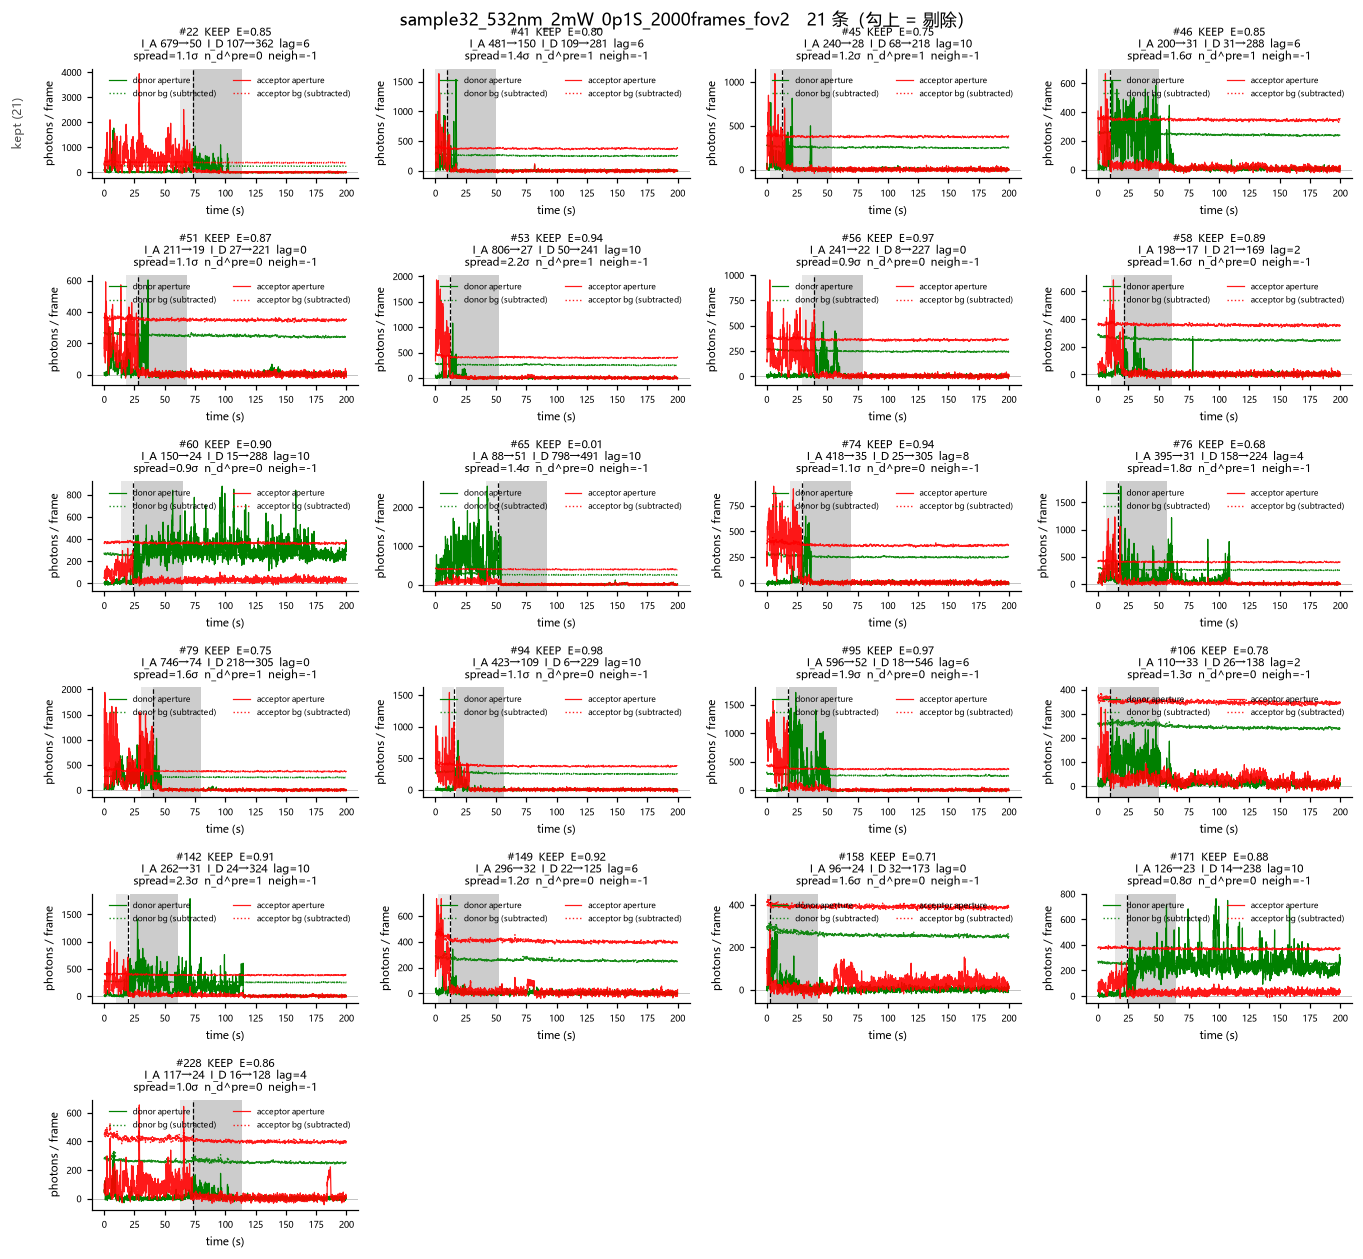

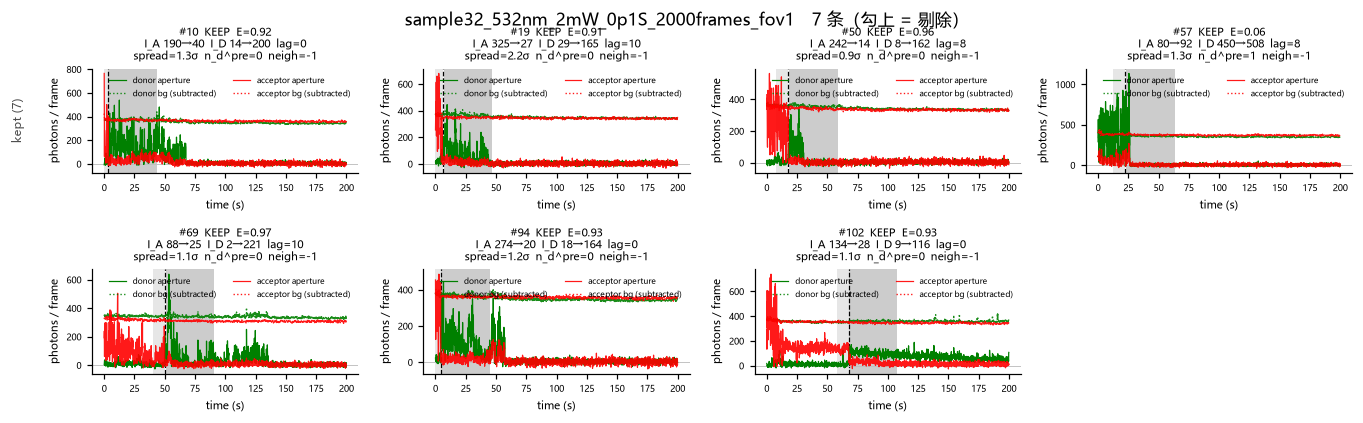

In [ ]:
import dataclasses

import ipywidgets as widgets
from IPython.display import display

PAGES = field_names()
_cache = {}                  # {name: (recs, td, ta, res, ex, cal)}
_dirty = set()               # 有改动还没落盘的视野

_title = widgets.HTML()
_fig = widgets.Output()
_grid = widgets.HBox([])
_status = widgets.HTML()
_prev = widgets.Button(description='← 上一页', layout=widgets.Layout(width='110px'))
_next = widgets.Button(description='下一页 →', layout=widgets.Layout(width='110px'))
_save = widgets.Button(description='保存本页', button_style='primary',
                       layout=widgets.Layout(width='110px'))
_save_all = widgets.Button(description='全部保存', layout=widgets.Layout(width='110px'))
_bar = widgets.HBox([_prev, _next, _save, _save_all])


def _prepare(name):
    if name not in _cache:
        _cache[name] = load_field(name, verbose=False)
        REJECT.setdefault(name, read_reject(name))
    return _cache[name]


def _sync():
    name = PAGES[CURRENT['i']]
    recs, *_ = _prepare(name)
    drop = set(REJECT.get(name, []))
    kept = [r.E for r in recs if r.emitter_id not in drop]
    flag = ('<span style="color:#b45309">未保存</span>' if name in _dirty
            else '<span style="color:#15803d">已保存</span>')
    _status.value = (f'剔除 {sorted(drop) or "无"}　→　留 {len(kept)} 条'
                     + (f'　E 中位 {np.median(kept):.3f}' if kept else '')
                     + f'　{flag}')


def _save_one(name, quiet=False):
    recs, td, ta, res, ex, cal = _prepare(name)
    drop = set(REJECT.get(name, []))
    kept = [r for r in res if r.emitter_id not in drop]
    fr.save_bundle(field_dir(name),
                   records=[r if r.emitter_id not in drop
                            else dataclasses.replace(r, keep=False,
                                                     reasons=['manual'])
                            for r in recs],
                   results=kept, traces_d=td, traces_a=ta, cal=cal,
                   ex_time=ex, title=name, include_all=False,
                   include_rejected=True, suffix=SUFFIX, ncols=4, verbose=False)
    write_reject(name, drop)
    _dirty.discard(name)
    if not quiet:
        print(f'  {name}: 落盘 {len(kept)} 条 -> {field_dir(name).name}/')
    if name == PAGES[CURRENT['i']]:
        _sync()                      # 状态行立刻变"已保存"
    return len(kept)


def _render():
    name = PAGES[CURRENT['i']]
    recs, td, ta, res, ex, cal = _prepare(name)
    with _fig:
        _fig.clear_output(wait=True)
        fig = fr.viz.plot_pair_gallery(recs, ta, td, which='kept',
                                       n=len(recs), ncols=4, ex_time=ex)
        fig.suptitle(f'{name}　{len(recs)} 条（勾上 = 剔除）', fontsize=11, y=1.0)
        display(fig)
    boxes = {}
    for r in recs:
        boxes[r.emitter_id] = widgets.Checkbox(
            value=r.emitter_id in set(REJECT.get(name, [])),
            description=f'✗ #{r.emitter_id}   E={r.E:.2f}',
            indent=False, layout=widgets.Layout(width='205px'))
        boxes[r.emitter_id].observe(
            lambda ch, _i=r.emitter_id, _n=name: _toggle(_n, _i, ch['new']),
            names='value')
    _grid.children = tuple(boxes.values())
    _title.value = (f'<b>{CURRENT["i"] + 1} / {len(PAGES)}</b>　{name}　'
                    f'{len(recs)} 条')
    _sync()


def _toggle(name, i, on):
    drop = set(REJECT.get(name, []))
    (drop.add if on else drop.discard)(int(i))
    REJECT[name] = sorted(int(v) for v in drop)
    _dirty.add(name)
    _sync()


def _goto(step):
    name = PAGES[CURRENT['i']]
    if name in _dirty:                      # 换页前自动存
        _save_one(name)
    CURRENT['i'] = (CURRENT['i'] + step) % len(PAGES)
    _render()


def _save_current(_btn=None):
    _save_one(PAGES[CURRENT['i']])
    _sync()


def _save_everything(_btn=None):
    for k, name in enumerate(PAGES, 1):
        print(f'[{k}/{len(PAGES)}]', end='')
        _save_one(name)
    _render()


CURRENT = {'i': 0}
_prev.on_click(lambda _b: _goto(-1))
_next.on_click(lambda _b: _goto(+1))
_save.on_click(_save_current)
_save_all.on_click(_save_everything)

_render()
display(widgets.VBox([_bar, _title, _status, _fig, _grid]))


## 池化（按组）

`GROUPS` 决定哪些视野合成一组，每组的结果写到 `STATS_DIR/<组名>/`：

- `E_pooled_manual.png` —— E 分布 + E vs 受体亮度
- `E_pooled_manual.csv` —— 逐分子的全部列（带 `field`），统计随时能重算

组的顺序和命名由你定（例如 `'fov1_fov4': ['fov1', 'fov4']`）。
若某视野还没保存过 `fret_manual.csv`，这一格会提示并跳过它。



=== all ===


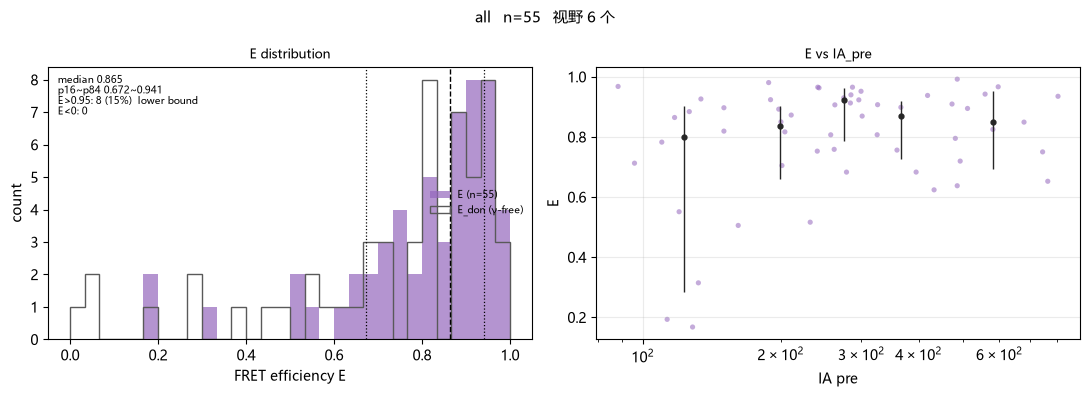

  n=55  中位 0.865  p16~p84 0.672~0.941  E<0: 0  E>1: 0
                                          n    中位   p16
field                                                  
sample32_532nm_2mW_0p1S_2000frames_fov1   6 0.928 0.920
sample32_532nm_2mW_0p1S_2000frames_fov2  19 0.873 0.752
sample32_532nm_2mW_0p1S_2000frames_fov3   9 0.817 0.651
sample32_532nm_2mW_0p1S_2000frames_fov4   5 0.825 0.759
sample32_532nm_2mW_0p1S_2000frames_fov5   8 0.838 0.551
sample32_532nm_2mW_0p1S_2000frames_fov6   8 0.660 0.343
  -> G:\PacBio\近观DNA_FRET\20261123\FRET_stats\all


In [ ]:
def _results_from(df):
    return [fr.FretResult(emitter_id=int(r.idx), frame=int(r.frame_j),
                          lag=int(r.lag), x=float(r.x_px), y=float(r.y_px),
                          n_pre=int(r.n_pre), n_on=int(r.n_on),
                          IA_pre=float(r.I_A_pre), ID_pre=float(r.I_D_pre),
                          IA_post=float(r.I_A_post), ID_post=float(r.I_D_post),
                          S_A=float(r.S_A), E=float(r.E), E_don=float(r.E_don),
                          snr_A=float(r.snr_A), t_bleach=float(r.t_bleach_s))
            for r in df.itertuples()]


def pooled_frame(keys):
    parts = []
    for name in pick(keys):
        p = field_dir(name) / fr.filenames(SUFFIX)['fret_csv']
        if not p.is_file():
            print(f'  [!] {name}: 没有 {p.name}（先在上面保存一次），跳过')
            continue
        df = pd.read_csv(p, encoding='utf-8-sig')
        df.insert(0, 'field', name)
        parts.append(df)
    return pd.concat(parts, ignore_index=True) if parts else pd.DataFrame()


for gname, keys in GROUPS.items():
    df = pooled_frame(keys)
    print(f'\n=== {gname} ===')
    if df.empty:
        print('  空')
        continue
    out_dir = STATS_DIR / gname
    out_dir.mkdir(parents=True, exist_ok=True)
    csv_p = out_dir / f'E_pooled{SUFFIX}.csv'
    df.to_csv(csv_p, index=False, encoding='utf-8-sig')

    res = _results_from(df)
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    fr.viz.plot_efficiency(res, ax=axes[0])
    fr.viz.plot_efficiency_vs_brightness(res, ax=axes[1], key='IA_pre')
    fig.suptitle(f'{gname}   n={len(res)}   视野 {df.field.nunique()} 个',
                 fontsize=11)
    fig.tight_layout()
    png_p = out_dir / f'E_pooled{SUFFIX}.png'
    fig.savefig(png_p, dpi=200, bbox_inches='tight', facecolor='white')
    plt.show()

    E = df.E.to_numpy(float)
    print(f'  n={E.size}  中位 {np.median(E):.3f}  p16~p84 '
          f'{np.percentile(E, 16):.3f}~{np.percentile(E, 84):.3f}  '
          f'E<0: {int((E < 0).sum())}  E>1: {int((E > 1).sum())}')
    print(df.groupby('field').E.agg(n='size', 中位='median',
                                    p16=lambda v: np.percentile(v, 16))
          .to_string(float_format=lambda v: f'{v:.3f}'))
    print(f'  -> {out_dir}')
